# 02 · Construcción de features

**Objetivo:** convertir los ráster (millones de píxeles) en una **tabla** que un modelo pueda usar.

**Idea clave:** no hay que etiquetar imágenes a mano. `lossyear` ya nos dice qué pasó, así que la etiqueta sale sola.

- Dividimos la zona en **celdas de ~1 km × 1 km**.
- Una **fila** de la tabla = una celda observada hasta un año `T`.
- Las **columnas** (features) resumen lo que se sabía hasta `T`.
- La **etiqueta** `alerta` = 1 si esa celda pierde bastante bosque en el año `T + 1`.

Así el modelo aprende: *"dado lo que pasó hasta hoy, ¿dónde habrá pérdida el próximo año?"*

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

# Encuentra la raíz del repo, sin importar desde dónde abras el notebook
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

ZONA = "guaviare"   # nombre de la zona usado en recortar(..., zona="guaviare")
PROCESSED = RAIZ / "data" / "processed"

plt.rcParams["figure.dpi"] = 100


BOSQUE_MIN = 30     # % mínimo para llamar "bosque" (el mismo del notebook 01)
CELDA_PX = 36       # 36 píxeles ≈ 1 km por lado (36 × ~28 m)
UMBRAL_HA = 2.0     # una celda tiene "alerta" si pierde >= 2 ha de bosque en el año siguiente

## 1. Cargar las capas

In [2]:
def leer_capa(capa):
    ruta = PROCESSED / f"{ZONA}_{capa}.tif"
    if not ruta.exists():
        raise FileNotFoundError(f"No encuentro {ruta}. ¿Ejecutaste descargar_tesela() y recortar()?")
    with rasterio.open(ruta) as src:
        datos = src.read(1)
        meta = {"crs": src.crs, "bounds": src.bounds, "res": src.res}
    return datos, meta


tc, meta = leer_capa("treecover2000")
ly, _ = leer_capa("lossyear")
dm, _ = leer_capa("datamask")

assert tc.shape == ly.shape == dm.shape, "Las tres capas deben tener la misma forma"

lat_centro = (meta["bounds"].top + meta["bounds"].bottom) / 2
ancho_m = meta["res"][0] * 111_320 * np.cos(np.radians(lat_centro))
alto_m = meta["res"][1] * 111_320
HA_POR_PIXEL = ancho_m * alto_m / 10_000

## 2. Agrupar píxeles en celdas (el truco del `reshape`)

Para sumar los píxeles de cada celda de 36×36 sin hacer bucles lentos, reorganizamos el arreglo con `reshape`.
Primero un ejemplo pequeño: un arreglo de 4×4 que dividimos en celdas de 2×2.

In [3]:
juguete = np.arange(16).reshape(4, 4)
print(juguete)
print("Suma por cada celda de 2×2:")
print(juguete.reshape(2, 2, 2, 2).sum(axis=(1, 3)))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]
Suma por cada celda de 2×2:
[[10 18]
 [42 50]]


La forma es `reshape(n_celdas_fila, píxeles, n_celdas_col, píxeles)` y se suma sobre los ejes 1 y 3.
Recortamos los bordes sobrantes para que el tamaño sea múltiplo de la celda.

In [4]:
n_f = tc.shape[0] // CELDA_PX
n_c = tc.shape[1] // CELDA_PX
alto, ancho = n_f * CELDA_PX, n_c * CELDA_PX
tc, ly, dm = tc[:alto, :ancho], ly[:alto, :ancho], dm[:alto, :ancho]

bosque = (tc >= BOSQUE_MIN) & (dm == 1)
print(f"Cuadrícula: {n_f} × {n_c} = {n_f * n_c:,} celdas")


def sumar_por_celda(mascara):
    # cuenta los píxeles True dentro de cada celda -> matriz (n_f, n_c)
    return mascara.reshape(n_f, CELDA_PX, n_c, CELDA_PX).sum(axis=(1, 3))

Cuadrícula: 111 × 111 = 12,321 celdas


## 3. Contar bosque y pérdida por celda y por año

- `bosque_2000[i, j]` = píxeles de bosque que había en la celda en el año 2000.
- `perdida[a, i, j]` = píxeles de bosque perdidos en el año `2000 + a`.

In [5]:
bosque_2000 = sumar_por_celda(bosque)

perdida = np.zeros((25, n_f, n_c), dtype=np.int32)   # el índice 0 no se usa
for a in range(1, 25):
    perdida[a] = sumar_por_celda(bosque & (ly == a))

# Verificación: lo agregado por celdas debe coincidir con el total del ráster
assert perdida.sum() == (bosque & (ly > 0)).sum()
print("Verificación OK: el agrupado coincide con el ráster completo")

Verificación OK: el agrupado coincide con el ráster completo


## 4. Ubicar cada celda en el mapa

Guardamos la latitud y longitud del centro de cada celda para poder dibujarlas después.

In [6]:
b = meta["bounds"]
lado_lon = CELDA_PX * meta["res"][0]
lado_lat = CELDA_PX * meta["res"][1]
lon_centro = b.left + (np.arange(n_c) + 0.5) * lado_lon
lat_centro_celdas = b.top - (np.arange(n_f) + 0.5) * lado_lat

print(f"Celda ≈ {lado_lon:.4f}° × {lado_lat:.4f}° (≈ 1 km)")

Celda ≈ 0.0090° × 0.0090° (≈ 1 km)


## 5. Construir la tabla de features

Para cada año de observación `T` (de 2003 a 2023) calculamos:

| Columna | Significado |
|---|---|
| `pct_bosque_2000` | % de la celda con bosque en 2000 |
| `pct_bosque_restante` | % de la celda con bosque que queda al final del año `T` |
| `perdida_acum_pct` | % del bosque del 2000 de esa celda ya perdido hasta `T` |
| `perdida_ha_ultimo` | hectáreas perdidas en el año `T` |
| `perdida_ha_ult3` | hectáreas perdidas en los últimos 3 años (`T-2` a `T`) |
| `perdida_vecinas_ha_ultimo` | promedio de ha perdidas en las 8 celdas vecinas en `T` |
| `perdida_vecinas_ha_ult3` | igual, en los últimos 3 años |
| `perdida_ha_siguiente` | **resultado**: ha perdidas en `T + 1` (**no** es una feature) |
| `alerta` | **etiqueta**: 1 si `perdida_ha_siguiente >= UMBRAL_HA` |

`lat`, `lon`, `fila` y `col` solo sirven para dibujar mapas; no entran al modelo.

**Regla de oro:** una feature de `T` solo puede usar información hasta `T`. Si usara el año `T + 1`, el modelo "haría trampa" (fuga de datos).

In [7]:
def media_vecinas(mapa):
    # promedio de las 8 celdas vecinas (fuera del borde cuenta como 0)
    p = np.pad(mapa.astype(float), 1)
    suma = sum(
        p[1 + di:1 + di + mapa.shape[0], 1 + dj:1 + dj + mapa.shape[1]]
        for di in (-1, 0, 1) for dj in (-1, 0, 1) if (di, dj) != (0, 0)
    )
    return suma / 8


filas_idx, cols_idx = np.meshgrid(np.arange(n_f), np.arange(n_c), indexing="ij")
filas_idx, cols_idx = filas_idx.ravel(), cols_idx.ravel()
ids = filas_idx * n_c + cols_idx
pix_celda = CELDA_PX ** 2

acum = np.cumsum(perdida, axis=0)   # acum[a] = píxeles perdidos desde 2001 hasta 2000 + a

tablas = []
for T in range(3, 24):   # observamos hasta el año 2000 + T y predecimos el año 2000 + T + 1
    p_ultimo = perdida[T]
    p_ult3 = perdida[T - 2:T + 1].sum(axis=0)
    restante = bosque_2000 - acum[T]
    acum_pct = np.divide(acum[T], bosque_2000, out=np.zeros(bosque_2000.shape), where=bosque_2000 > 0) * 100

    tablas.append(pd.DataFrame({
        "celda_id": ids,
        "fila": filas_idx,
        "col": cols_idx,
        "lat": lat_centro_celdas[filas_idx],
        "lon": lon_centro[cols_idx],
        "anio_obs": 2000 + T,
        "anio_pred": 2000 + T + 1,
        "pct_bosque_2000": bosque_2000.ravel() / pix_celda * 100,
        "pct_bosque_restante": restante.ravel() / pix_celda * 100,
        "perdida_acum_pct": acum_pct.ravel(),
        "perdida_ha_ultimo": p_ultimo.ravel() * HA_POR_PIXEL,
        "perdida_ha_ult3": p_ult3.ravel() * HA_POR_PIXEL,
        "perdida_vecinas_ha_ultimo": media_vecinas(p_ultimo).ravel() * HA_POR_PIXEL,
        "perdida_vecinas_ha_ult3": media_vecinas(p_ult3).ravel() * HA_POR_PIXEL,
        "perdida_ha_siguiente": perdida[T + 1].ravel() * HA_POR_PIXEL,
    }))

panel = pd.concat(tablas, ignore_index=True)
panel["alerta"] = (panel["perdida_ha_siguiente"] >= UMBRAL_HA).astype(int)

# Solo celdas que todavía tienen bosque que perder (>= 1 % de la celda)
panel = panel[panel["pct_bosque_restante"] >= 1].reset_index(drop=True)

assert (panel["anio_obs"] < panel["anio_pred"]).all()
print(f"Tabla final: {len(panel):,} filas × {panel.shape[1]} columnas")
panel.head()

Tabla final: 258,732 filas × 16 columnas


,celda_id,fila,col,lat,lon,anio_obs,anio_pred,pct_bosque_2000,pct_bosque_restante,perdida_acum_pct,perdida_ha_ultimo,perdida_ha_ult3,perdida_vecinas_ha_ultimo,perdida_vecinas_ha_ult3,perdida_ha_siguiente,alerta
0,0,0,0,2.4955,-73.4955,2003,2004,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,1,0,1,2.4955,-73.4865,2003,2004,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,2,0,2,2.4955,-73.4775,2003,2004,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,3,0,3,2.4955,-73.4685,2003,2004,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,4,0,4,2.4955,-73.4595,2003,2004,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0


## 6. Revisar el balance de clases

Porcentaje de celdas con `alerta = 1` en cada año. Si fuera casi 0 % el modelo no tendría de dónde aprender; si fuera muy alto, la alerta no distinguiría nada.

Con `UMBRAL_HA = 2.0` la tasa de alertas queda entre 4.1 % (2005) y 17.4 % (2018), un rango adecuado para entrenar, por lo que se mantiene ese umbral.

In [8]:
balance = panel.groupby("anio_pred")["alerta"].agg(alertas="sum", celdas="count", tasa="mean")
balance["tasa"] = (balance["tasa"] * 100).round(2)
balance

,alertas,celdas,tasa
anio_pred,,,
2004,1425,12321,11.57
2005,507,12321,4.11
2006,1471,12321,11.94
2007,982,12321,7.97
2008,1185,12321,9.62
2009,1274,12321,10.34
2010,1206,12321,9.79
2011,1412,12321,11.46
2012,997,12321,8.09


## 7. Dividir en entrenamiento, validación y prueba **por tiempo**

No mezclamos años al azar: el modelo no puede ver el futuro. Dividimos según el año que se quiere predecir:

| Conjunto | Años predichos | Para qué |
|---|---|---|
| `train` | hasta 2020 | aprender |
| `val` | 2021 a 2022 | ajustar decisiones |
| `test` | 2023 a 2024 | nota final, una sola vez |

In [9]:
def asignar_conjunto(anio_pred):
    if anio_pred <= 2020:
        return "train"
    if anio_pred <= 2022:
        return "val"
    return "test"


panel["conjunto"] = panel["anio_pred"].map(asignar_conjunto)
resumen = panel.groupby("conjunto")["alerta"].agg(filas="count", alertas="sum", tasa="mean")
resumen["tasa"] = (resumen["tasa"] * 100).round(2)
print(resumen)

assert set(resumen.index) == {"train", "val", "test"}

           filas  alertas   tasa
conjunto                        
test       24636     1582   6.42
train     209457    21134  10.09
val        24639     2432   9.87


## 8. Verificación visual y guardado

Un mapa rápido de la pérdida acumulada por celda: debe parecerse al mapa del notebook 01 pero más "pixelado".

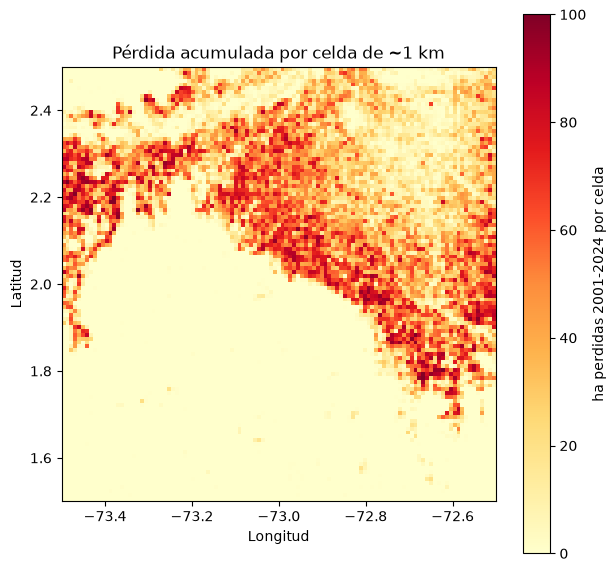

In [10]:
plt.figure(figsize=(7, 7))
plt.imshow(
    acum[24] * HA_POR_PIXEL,
    extent=(b.left, b.left + n_c * lado_lon, b.top - n_f * lado_lat, b.top),
    cmap="YlOrRd",
)
plt.colorbar(label="ha perdidas 2001-2024 por celda")
plt.title("Pérdida acumulada por celda de ~1 km")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()

In [11]:
import json

panel.to_csv(PROCESSED / f"panel_{ZONA}.csv", index=False)

meta_celdas = {
    "zona": ZONA,
    "celda_px": CELDA_PX,
    "lado_lon": lado_lon,
    "lado_lat": lado_lat,
    "bosque_min": BOSQUE_MIN,
    "umbral_ha": UMBRAL_HA,
    "ha_por_pixel": float(HA_POR_PIXEL),
}
(PROCESSED / f"meta_celdas_{ZONA}.json").write_text(json.dumps(meta_celdas, indent=2))
print("Guardados panel y meta en data/processed/")

Guardados panel y meta en data/processed/


In [13]:
import sys

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.forestguard.features import construir_panel

panel_py, _ = construir_panel(ZONA, bosque_min=BOSQUE_MIN, celda_px=CELDA_PX,
                              umbral_ha=UMBRAL_HA, procesado=PROCESSED, guardar=False)
pd.testing.assert_frame_equal(panel, panel_py)
print("features.py reproduce exactamente el notebook")

features.py reproduce exactamente el notebook
